# Relatório: Q-Learning x SARSA no Taxi-v4

**Objetivo:** comparar os algoritmos Q-Learning e SARSA no ambiente `Taxi-v4` em duas versões:
- **Determinístico**: o táxi sempre vai na direção escolhida.
- **Estocástico (chuva)**: o táxi vai na direção escolhida com 60% de chance e escorrega para o lado com 40%.

**Recompensas:** -1 por passo, +20 pela entrega e -10 por ação ilegal (pegar ou deixar o passageiro no lugar errado). O episódio termina na entrega ou após 200 passos.

**Hiperparâmetros** (iguais para os dois algoritmos e os dois ambientes), escolhidos para um aprendizado rápido:

| Parâmetro | Valor | Por quê |
|---|---|---|
| α (taxa de aprendizado) | 0.5 | Atualizações grandes: o agente aprende rápido com poucas experiências. |
| γ (fator de desconto) | 0.99 | Uma entrega leva de 10 a 30 passos, e o agente precisa "enxergar" o +20 de longe (ver seção 3). |
| ε (exploração) | 0.2 → 0.05, multiplicado por 0.99 a cada episódio | O ambiente é pequeno (500 estados), então pouca exploração já basta, e ela cai rápido para o agente passar a usar o que aprendeu. |
| Episódios | 10.000 por treino, 5 treinos por configuração | Os 5 treinos mostram se o resultado se repete ou depende da sorte. |

In [1]:
from pathlib import Path

import gymnasium as gym
import numpy as np

from report_utils import load_rewards, plot_comparison, results_table, transfer_table

DATA_DIR = Path.cwd().parent / "data"

In [2]:
REWARD_GOAL = 8

LABELS = {
    "qlearning_deterministic": "Q-Learning (determinístico)",
    "sarsa_deterministic":     "SARSA (determinístico)",
    "qlearning_stochastic":    "Q-Learning (estocástico)",
    "sarsa_stochastic":        "SARSA (estocástico)",
}

deterministic_env = gym.make("Taxi-v4")
stochastic_env = gym.make("Taxi-v4", is_rainy=True, rainy_probability=0.6)
envs = {name: stochastic_env if "stochastic" in name else deterministic_env for name in LABELS}

rewards = {name: load_rewards(DATA_DIR / "rewards", name) for name in LABELS}
N_RUNS = 5
q_tables = {
    name: [np.loadtxt(DATA_DIR / "q_tables" / f"{name}_run{run}.csv", delimiter=",") for run in range(1, N_RUNS + 1)]
    for name in LABELS
}

## 1. Curvas de aprendizado

Cada gráfico mostra a recompensa por episódio, como média das 5 runs:
- **Linha clara**: a recompensa de cada episódio.
- **Linha grossa**: a média móvel de 100 episódios.
- **Tracejado**: o objetivo de recompensa (8).
- **Quadro interno**: zoom nos primeiros 1000 episódios.

### Q-Learning x SARSA: determinístico

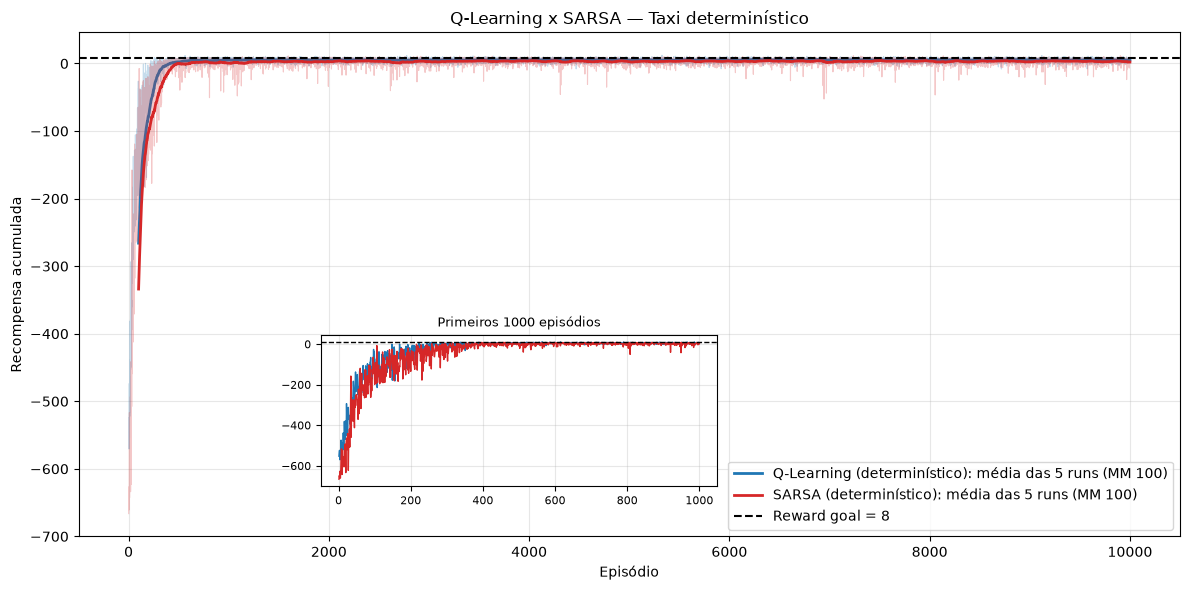

In [3]:
plot_comparison(rewards, LABELS, ["qlearning_deterministic", "sarsa_deterministic"], "Q-Learning x SARSA — Taxi determinístico", REWARD_GOAL)

- O **Q-Learning** melhora rápido e se estabiliza entre ~500 e 1000 episódios, perto do objetivo (~5).
- O **SARSA** aprende um pouco mais devagar no início (no episódio 300, está em -44 contra -14 do Q-Learning), mas também converge e se estabiliza perto do objetivo (~1 a 4), ligeiramente abaixo do Q-Learning. No fim do treino, nenhum episódio fica preso até o limite de 200 passos.

### Q-Learning x SARSA: estocástico

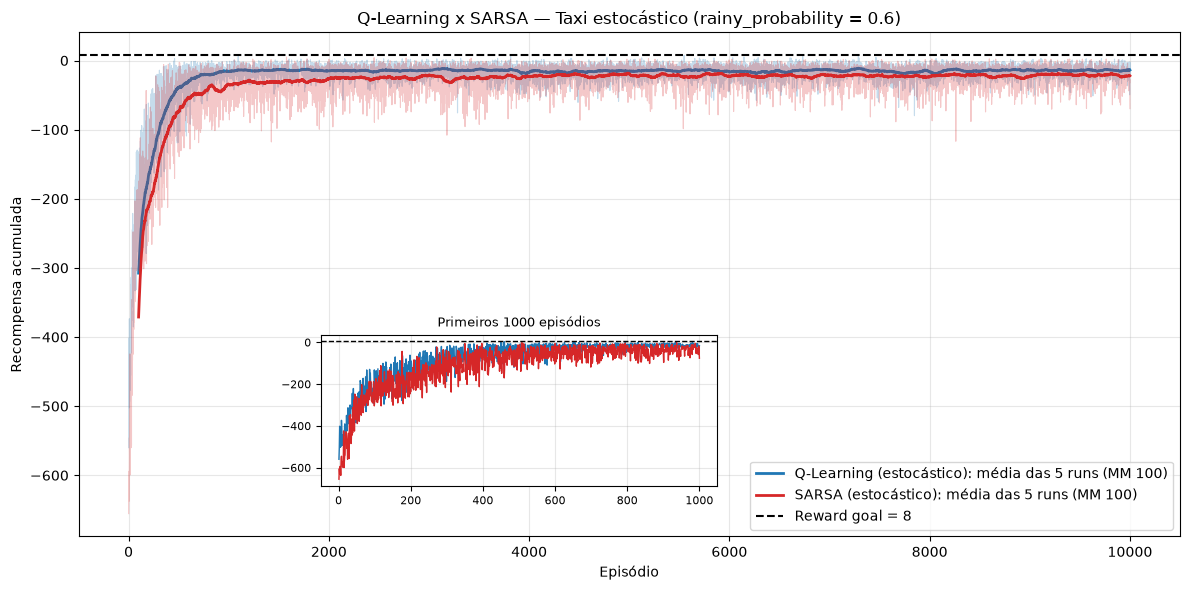

In [4]:
plot_comparison(rewards, LABELS, ["qlearning_stochastic", "sarsa_stochastic"], "Q-Learning x SARSA — Taxi estocástico (rainy_probability = 0.6)", REWARD_GOAL)

- Os dois aprendem mais devagar e terminam mais baixo do que no ambiente determinístico. O objetivo (8) fica fora de alcance, porque os escorregões aumentam o número de passos de cada entrega.
- O **Q-Learning** se estabiliza em ~-15 a partir de ~1000 episódios.
- O **SARSA** é mais lento (ainda em ~-73 no episódio 500) e se estabiliza um pouco abaixo, entre -30 e -20.

### Q-Learning: determinístico x estocástico

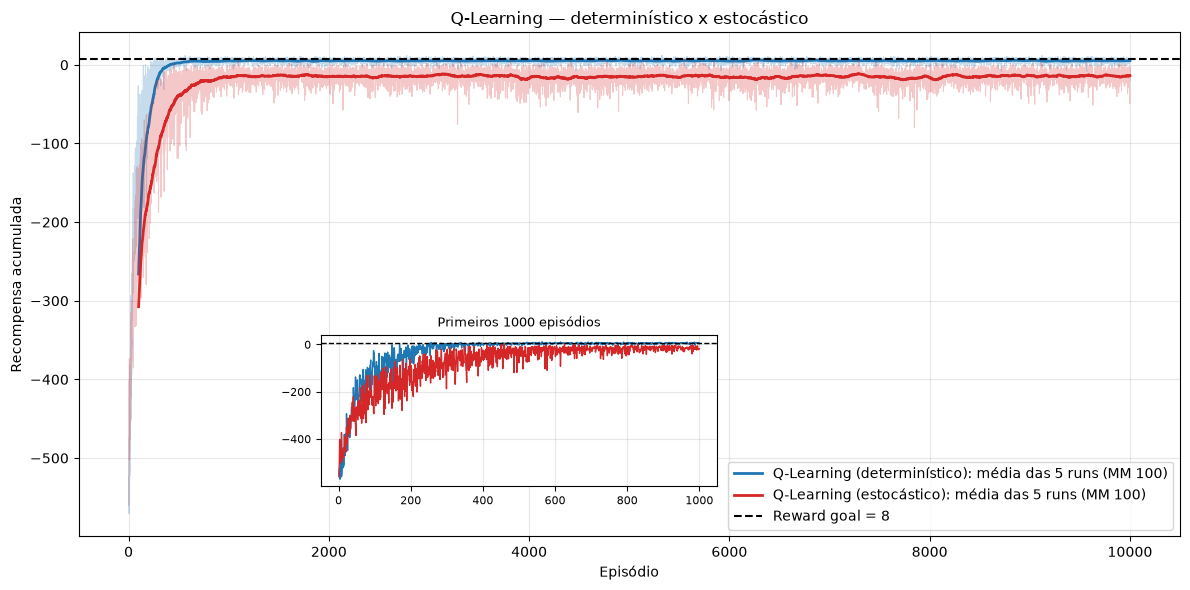

In [5]:
plot_comparison(rewards, LABELS, ["qlearning_deterministic", "qlearning_stochastic"], "Q-Learning — determinístico x estocástico", REWARD_GOAL)

- Com chuva, a curva tem o mesmo formato, mas sobe mais devagar e termina ~20 pontos mais baixa. Os escorregões fazem cada entrega custar mais passos.

### SARSA: determinístico x estocástico

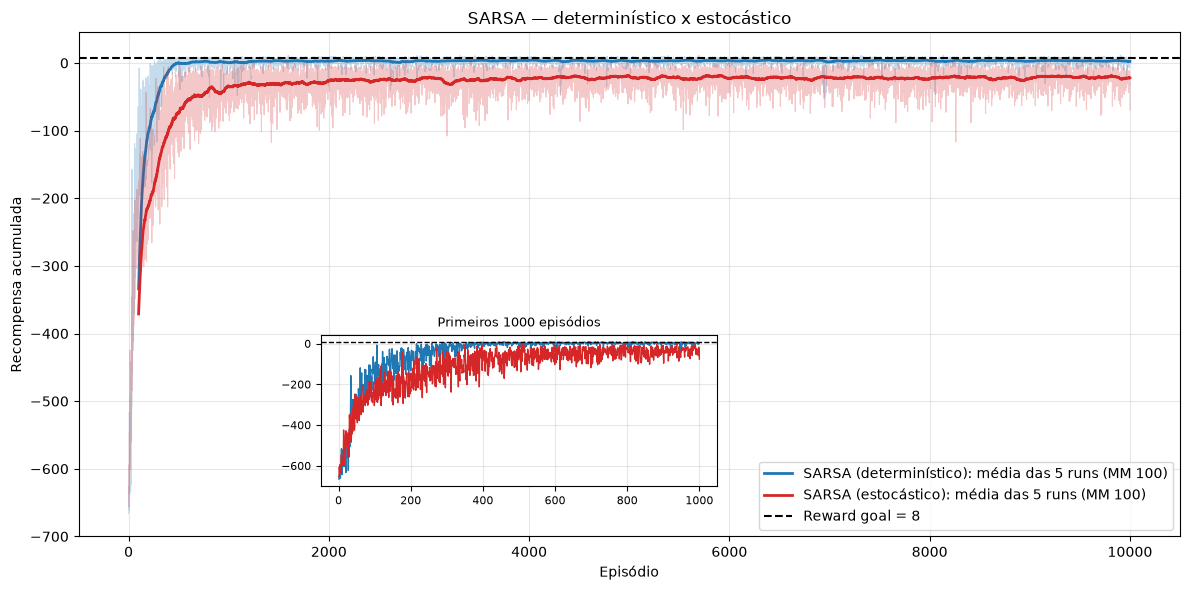

In [6]:
plot_comparison(rewards, LABELS, ["sarsa_deterministic", "sarsa_stochastic"], "SARSA — determinístico x estocástico", REWARD_GOAL)

- O padrão é o mesmo do Q-Learning: com chuva, o SARSA aprende mais devagar e termina mais baixo (de ~3 para ~-21).
- A queda é um pouco maior que a do Q-Learning, ou seja, o SARSA sofre mais com o não determinismo durante o treino.

## 2. Resultados

A Q-table final de cada um dos 5 treinos é testada sem exploração (sempre a melhor ação) em 100 episódios, o que dá 500 episódios por configuração.
- **Recompensa média**: média dos últimos 1000 episódios de treino das 5 runs.
- **Timesteps médios e desvio padrão**: número de passos até a entrega, contando só os episódios em que houve entrega.
- **Taxa de sucesso**: % de episódios em que o passageiro foi entregue antes do limite de 200 passos (média das 5 runs).
- **Desvio da taxa de sucesso entre runs**: quanto o resultado muda de um treino para outro.

In [7]:
results_table(rewards, q_tables, envs, LABELS)

,Recompensa média (últ. 1000 ep. de treino),Timesteps médios,Desvio padrão dos timesteps,Taxa de sucesso (%),Desvio da taxa de sucesso entre runs
Configuração,,,,,
Q-Learning (determinístico),5.07,13.36,2.88,100.0,0.00
SARSA (determinístico),3.18,13.87,3.27,81.8,14.04
Q-Learning (estocástico),-14.30,27.06,11.38,83.8,19.84
SARSA (estocástico),-20.88,29.99,15.50,83.0,13.82


## 3. Q-Learning x SARSA

**Eficiência no aprendizado.** O Q-Learning chega a um bom desempenho mais cedo nos dois ambientes. No episódio 300, a média móvel do Q-Learning determinístico já está em -14, enquanto a do SARSA está em -44. No estocástico, no episódio 500, os valores são -40 contra -73.

**Desempenho final.** Quando entregam o passageiro, os dois usam um número de passos parecido: ~13 a 14 no determinístico e ~27 a 30 no estocástico. A diferença aparece na confiabilidade da política, no ambiente determinístico:
- O **Q-Learning** entrega em 100% dos testes, em todos os 5 treinos.
- O **SARSA** entrega em ~82%, e o valor varia bastante de um treino para outro (±14 pontos). Nos demais episódios ele fica preso em *loop* até o limite de 200 passos.

No ambiente estocástico, os dois ficam em ~83% de sucesso, também com grande variação entre treinos (seção 4).

**Por que essa diferença?** O Q-Learning aprende o valor da *melhor* ação possível, mesmo quando, durante o treino, ele próprio está explorando. O SARSA aprende o valor da ação que ele *realmente* toma, incluindo as ações aleatórias da exploração. Por isso o SARSA aprende mais devagar e fica com estimativas menos precisas em alguns estados. Durante o treino, as ações aleatórias o tiram desses *loops*. Sem exploração, ele pode ficar preso.

**O papel de γ.** Numa primeira versão dos experimentos usamos γ = 0.7, e o SARSA não conseguia aprender: ficava preso em 40% (determinístico) e 73% (estocástico) dos episódios de treino. O γ define o quanto o agente valoriza recompensas futuras. Com γ = 0.7, o +20 da entrega vale só ~0.6 quando visto a 10 passos de distância, então longe do destino todas as ações pareciam igualmente boas. O Q-Learning ainda conseguia diferenciá-las; o SARSA, com o ruído da exploração, não. Com γ = 0.99, o +20 continua valendo ~18 a 10 passos, e os dois algoritmos aprendem. A lição é que o γ precisa ser compatível com a quantidade de passos que a tarefa exige.

## 4. Impacto do não determinismo

**No desempenho.** A chuva piora os dois algoritmos:
- **Passos por entrega**: sobem de ~13 a 14 para ~27 a 30, cerca do dobro.
- **Variação**: o desvio padrão dos timesteps sobe de ~3 para ~11 a 16, porque a mesma rota pode levar poucos ou muitos passos dependendo dos escorregões.
- **Recompensa de treino**: cai ~19 pontos no Q-Learning (5.1 → -14.3) e ~24 no SARSA (3.2 → -20.9).
- **Taxa de sucesso do Q-Learning**: cai de 100% para ~84%, com grande variação entre treinos (±20 pontos). Alguns treinos terminam com uma política que fica presa em *loop* em parte dos estados.

**Na política aprendida.** Com transições aleatórias, o resultado de uma ação muda de uma vez para outra. Com α = 0.5, cada atualização dá muito peso ao último resultado observado, então os valores Q ficam "pulando" em vez de convergir para a média. O agente precisa de mais experiência para estimar o valor de cada ação, e em alguns treinos termina com escolhas erradas em certos estados. A política nunca elimina os passos extras causados pelos escorregões; ela só pode tentar reduzi-los.

### Política determinística testada na chuva

Aqui as Q-tables treinadas **sem chuva** são testadas **com chuva**, e o resultado é comparado com os outros dois cenários (100 episódios por Q-table, 5 Q-tables por algoritmo).

In [8]:
transfer_table(q_tables, deterministic_env, stochastic_env)

Timesteps médios  \
Algoritmo  Cenário                                                          
Q-Learning treino determinístico → teste determinístico             13.36   
           treino determinístico → teste com chuva                  26.57   
           treino com chuva → teste com chuva                       27.06   
SARSA      treino determinístico → teste determinístico             13.87   
           treino determinístico → teste com chuva                  28.31   
           treino com chuva → teste com chuva                       29.99   

                                                         Desvio padrão dos timesteps  \
Algoritmo  Cenário                                                                     
Q-Learning treino determinístico → teste determinístico                         2.88   
           treino determinístico → teste com chuva                             10.64   
           treino com chuva → teste com chuva                                  11.38   
SARSA      treino determinístico → teste determinístico                         3.27   
           treino determinístico → teste com chuva                             12.47   
           treino com chuva → teste com chuva                                  15.50   

                                                         Taxa de sucesso (%)  \
Algoritmo  Cenário                                                             
Q-Learning treino determinístico → teste determinístico                100.0   
           treino determinístico → teste com chuva                      97.8   
           treino com chuva → teste com chuva                           83.8   
SARSA      treino determinístico → teste determinístico                 81.8   
           treino determinístico → teste com chuva                      83.6   
           treino com chuva → teste com chuva                           83.0   

                                                         Desvio da taxa de sucesso entre runs  
Algoritmo  Cenário                                                                             
Q-Learning treino determinístico → teste determinístico                                  0.00  
           treino determinístico → teste com chuva                                       2.77  
           treino com chuva → teste com chuva                                           19.84  
SARSA      treino determinístico → teste determinístico                                 14.04  
           treino determinístico → teste com chuva                                      14.91  
           treino com chuva → teste com chuva                                           13.82

- **A política determinística continua funcionando na chuva.** O Q-Learning treinado sem chuva entrega em ~98% dos episódios com chuva, mas precisa do dobro de passos (de ~13 para ~27) e com muito mais variação (desvio de ~3 para ~11).
- **Por que ela funciona?** Os escorregões são para os lados e com a mesma probabilidade, então a melhor direção para seguir continua sendo a mesma. A rota ótima não muda; o que muda é que o táxi às vezes sai dela e precisa voltar.
- **Por que ela foi até mais confiável que a política treinada na chuva** (98% contra 84%)? A política determinística foi aprendida com valores exatos, sem ruído. A treinada na chuva foi aprendida com valores ruidosos e, em alguns treinos, ficou com escolhas erradas em certos estados (ver acima). Isso indica que o não determinismo prejudica mais o *aprendizado* do que a política em si.
- No **SARSA**, os três cenários ficam parecidos (~82% a 84% de sucesso), e a chuva só aumenta o número de passos.

## 5. Conclusões

- Com γ = 0.99, **os dois algoritmos aprendem a tarefa** nos dois ambientes e usam um número de passos parecido por entrega.
- O **Q-Learning** aprende mais rápido e, no ambiente determinístico, tem uma política final mais confiável (100% de sucesso, contra ~82% do SARSA).
- O **não determinismo** dobra o número de passos por entrega, aumenta a variação e torna o aprendizado mais lento e menos confiável (o resultado muda mais de um treino para outro).
- Uma política aprendida sem chuva **continua válida na chuva**, porque a melhor rota é a mesma. Na prática, ela foi até mais confiável do que treinar direto no ambiente com chuva usando estes hiperparâmetros.
- A **escolha de γ** foi decisiva: com γ = 0.7, o SARSA não aprendia. Os hiperparâmetros importam tanto quanto o algoritmo.

**Limitações:** apenas 5 treinos por configuração; os mesmos hiperparâmetros foram usados para os dois algoritmos e os dois ambientes, sem ajuste. Um α menor no ambiente com chuva provavelmente deixaria os valores Q mais estáveis.